# AR segmentation — bootstrap ensemble viewer

Ten bootstrap members, each run at **its own best epoch**, over the **15 HelioFM
cubes** in `assets/infer_data`. One model per member × 15 frames = 150 inferences.

The members differ *only* in which 168 training frames they drew, so the spread
between them on a fixed frame is the bootstrap uncertainty of the fine-tune —
that spread is what this notebook is for.

| produced by | what | where |
|---|---|---|
| `run_bootstrap_inference.py` | AR probability per (member, frame) | `/efs/bathomas/ar_seg_bootstrap/168hrs_infer/<frame>/prob_<member>.nc` |
| same | normalized channel cube, once per frame | `.../<frame>/channels.nc` |
| same | one row per inference | `.../manifest.csv` |

Training provenance and the ensemble's validation statistics are in
`/efs/bathomas/ar_seg_bootstrap/168hrs/README.md`.

Runs on the default `python3` kernel — no torch, no GPU, it only reads files.
Everything is 4096×4096, so each display downsamples. **Sparse mask images use
block-max, not averaging** — AR covers ~0.6 % of a frame and averaging dissolves
it into the background.

## Two things to keep in mind when reading these

**1. Epoch selection used the same day as 6 of the 15 frames.** Each member's
epoch was chosen by best IoU on a validation set of Jan 15, 2011–2019. Six frames
here (`20120115_*`) are from **2012-01-15**, which is in that set. Those six are
*not* held out from model selection and will flatter the ensemble. The other nine
(2011-01-20, 2013-01-28, 2019-01-23) are clean. No frame is in any member's
training replicate — all 15 are January and every replicate is Feb 15–Dec 31.

**2. Some of the spread is epoch-choice noise, not bootstrap noise.** `finetune.py`
has no early stopping, and a single member's IoU oscillates ±0.03–0.05 between
epochs — comparable to the 0.033 across-member sd. Taking each member's argmax
epoch suppresses part of that but does not remove it.

## Setup

In [1]:
import glob
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sunpy.visualization.colormaps as sunpy_cm  # registers the sdoaia* colormaps
import xarray as xr
import yaml
from matplotlib.colors import LinearSegmentedColormap, ListedColormap, Normalize

INFER_ROOT = "/efs/bathomas/ar_seg_bootstrap/168hrs_infer"
SCALERS_PATH = "./assets/scalers.yaml"
THRESHOLD = 0.5  # matches evaluate_model's hardcoded threshold in finetune.py

# Best epoch per member by validation IoU, with the IoU it scored.
# Source: run_bootstrap_inference.BEST_EPOCH (re-derived from the wandb output.log
# of each run); tabulated in 168hrs/README.md.
BEST = {
    "boot01": (8, 0.5170), "boot02": (9, 0.5050), "boot03": (9, 0.5256),
    "boot04": (5, 0.5344), "boot05": (6, 0.5539), "boot06": (4, 0.4950),
    "boot07": (3, 0.4812), "boot08": (8, 0.4927), "boot09": (8, 0.4918),
    "boot10": (7, 0.5194),
}
MEMBERS = sorted(BEST)

# Frames whose day was used to pick the epochs — see the header.
SELECTION_DAY = "20120115"

frames = sorted(
    os.path.basename(d) for d in glob.glob(os.path.join(INFER_ROOT, "*"))
    if os.path.isdir(d)
)
scalers = yaml.safe_load(open(SCALERS_PATH))

print(f"{len(frames)} frames, {len(MEMBERS)} members\n")
print(f"{'frame':<16}{'members':>9}{'channels':>10}   note")
for f in frames:
    n = len(glob.glob(os.path.join(INFER_ROOT, f, "prob_*.nc")))
    ch = "yes" if os.path.exists(os.path.join(INFER_ROOT, f, "channels.nc")) else "MISSING"
    note = "epoch-selection day" if f.startswith(SELECTION_DAY) else ""
    print(f"{f:<16}{n:>9}{ch:>10}   {note}")

15 frames, 10 members

frame             members  channels   note
20110120_0100          10       yes   
20110120_0200          10       yes   
20110120_0300          10       yes   
20120115_0048          10       yes   epoch-selection day
20120115_0100          10       yes   epoch-selection day
20120115_0148          10       yes   epoch-selection day
20120115_0200          10       yes   epoch-selection day
20120115_0248          10       yes   epoch-selection day
20120115_0300          10       yes   epoch-selection day
20130128_1812          10       yes   
20130128_1912          10       yes   
20130128_2012          10       yes   
20190123_0200          10       yes   
20190123_0300          10       yes   
20190123_0400          10       yes   


## Palette

One sequential blue ramp carries every magnitude here (agreement, AR fraction),
so the same visual weight always means the same thing.

Checked with the data-viz palette validator:

| use | colours | result |
|---|---|---|
| member dots vs ensemble mean | `#2a78d6,#eb6834` `--mode light` | all checks pass |
| agreement contours over imagery | `#d95926,#199e70` `--mode dark` | all checks pass |
| mask fill, used alone on a panel | `#d55181` `--mode dark` | all checks pass |

Two deliberate departures, both forced by the data:

- **The agreement map is read as a gradient, not as ten steps.** Ten discrete
  levels of a single hue sit ~0.047 apart in lightness and fail the validator's
  `--ordinal` adjacent-ΔL check; no single-hue ramp can carry ten distinguishable
  steps. The colorbar does the work instead. Its light end starts at ramp step
  250 rather than 100, because here the lightest value drawn means "1 member
  called this AR" — a real detection, not nothing — so it must clear the surface.
- **The mask fill is magenta, not the usual cyan.** The AIA colormaps run
  black → green/gold → white, so cyan disappears over bright AR cores, which is
  exactly where the mask lies. Magenta and the aqua contour would fail a pairwise
  CVD check against each other, but they never share a figure.

In [2]:
# Sequential blue, steps 100 -> 700 of the validated ramp. Used where the light
# end genuinely means "near zero" and may recede toward the surface.
BLUE_STEPS = ["#cde2fb", "#b7d3f6", "#9ec5f4", "#86b6ef", "#6da7ec", "#5598e7",
              "#3987e5", "#2a78d6", "#256abf", "#1c5cab", "#184f95", "#104281", "#0d366b"]
SEQ = LinearSegmentedColormap.from_list("surya_blue", BLUE_STEPS)

# Agreement ramp, steps 250 -> 700. On the agreement map the lightest value drawn
# means "1 member called this AR" -- a real detection, not nothing (k=0 is masked
# out) -- so the light end must clear the surface. Step 250 is the lightest that
# does, at 2.06:1.
#
# Read as a gradient against the colorbar, not as 10 nameable steps: ten discrete
# levels of a single hue sit ~0.047 apart in lightness, well under what the eye
# resolves, and the validator fails this ladder under --ordinal for exactly that
# reason. No single-hue ramp can carry 10 distinguishable steps.
SEQ_AGREE = LinearSegmentedColormap.from_list("surya_blue_agree", BLUE_STEPS[3:])

SERIES_1 = "#2a78d6"   # categorical slot 1 (light surface) - individual members
SERIES_2 = "#eb6834"   # categorical slot 2 (light surface) - ensemble mean
CONTOUR = {0.5: "#d95926", 0.8: "#199e70"}  # dark-surface steps, drawn over imagery

# Mask fill for the per-member panels. Magenta because the AIA colormaps run
# black -> green/gold -> white: cyan sits inside that range and vanishes over
# bright AR cores, which is exactly where the mask is. Magenta is the one
# strongly off-colormap hue. Used alone on a panel, so it needs no pairwise
# CVD check -- it would fail one against the aqua contour, but the two never
# share a figure.
MASK_FILL = "#d55181"

INK = "#0b0b0b"        # primary ink
INK_2 = "#52514e"      # secondary ink
MUTED = "#898781"      # axis / tick labels
GRID = "#e1e0d9"       # hairline gridline

plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": INK_2,
    "text.color": INK, "xtick.color": MUTED, "ytick.color": MUTED,
    "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "font.size": 10,
})


def recessive(ax, grid_axis="y"):
    '''Push grid and axes behind the data, where chrome belongs.'''
    ax.grid(True, axis=grid_axis, lw=0.8, color=GRID)
    ax.set_axisbelow(True)
    return ax

## Helpers

In [3]:
def block_max(img, factor):
    '''Downsample by taking the max over each factor x factor block.

    Averaging would erase sparse features; max keeps any flagged pixel visible.
    Same helper as view_results.ipynb.
    '''
    h, w = img.shape[:2]
    h, w = h - h % factor, w - w % factor  # crop to a multiple of factor
    img = img[:h, :w]
    if img.ndim == 3:
        return img.reshape(h // factor, factor, w // factor, factor, img.shape[2]).max(axis=(1, 3))
    return img.reshape(h // factor, factor, w // factor, factor).max(axis=(1, 3))


def block_mean(img, factor):
    '''Downsample by averaging. For the smooth channel images, not for masks.'''
    h, w = img.shape[:2]
    h, w = h - h % factor, w - w % factor
    return img[:h, :w].reshape(h // factor, factor, w // factor, factor).mean(axis=(1, 3))


def load_probability(frame, member):
    '''One member's AR probability map for one frame, as float32 (H, W).'''
    path = os.path.join(INFER_ROOT, frame, f"prob_{member}.nc")
    with xr.open_dataset(path, engine="h5netcdf") as ds:
        return ds.ar_probability.values.astype(np.float32)


def load_channel(frame, channel):
    '''One channel image for one frame, converted to display units.

    Stored standardized; this undoes only the standardization, leaving the
    signum-log values the scaler's min/max (and so the colour bar) describe.
    Same choice as infer_file.to_display_units, and deliberately not a full
    inverse - undoing the log too would put the image on a different scale
    than its own colour bar.
    '''
    path = os.path.join(INFER_ROOT, frame, "channels.nc")
    with xr.open_dataset(path, engine="h5netcdf") as ds:
        normalized = ds[channel].values.astype(np.float32)
    s = scalers[channel]
    return normalized * (s["std"] + s["epsilon"]) + s["mean"]


def channel_clim(channel, img):
    '''Per-frame display limits, from percentiles rather than the scaler.

    The scaler's min/max span the whole 2010-2019 archive and are set by flares.
    On a typical frame aia94 reaches a 99.8th percentile of ~0.08 against a
    scaler max of 5.10, so scaling to the scaler puts the entire disk in the
    bottom 2% of the colour range and renders it black. A per-frame percentile
    stretch is the usual solar-imaging choice and is what makes active regions
    legible under the mask overlay.

    Subsampled 4x in each axis: these are display limits, and sorting 16.8M
    values for them is wasted work.
    '''
    sub = img[::4, ::4]
    if "hmi" in channel:
        # Diverging colormaps must stay centred on zero or the sign reads wrong.
        v = float(np.percentile(np.abs(sub), 99.5))
        return -v, v
    lo, hi = np.percentile(sub, [0.5, 99.8])
    return float(lo), float(hi)


def channel_cmap(channel):
    if channel == "hmi_v":
        return plt.get_cmap("bwr")
    key = "hmimag" if channel.startswith("hmi") else f"sdo{channel}"
    return sunpy_cm.cmlist[key]


def agreement_map(frame, members=MEMBERS, threshold=THRESHOLD):
    '''Per-pixel count of members calling AR, as uint8 in [0, len(members)].

    Accumulated one member at a time: holding all ten float32 maps at once would
    be 1.3 GB for no reason.
    '''
    count = None
    for m in members:
        mask = load_probability(frame, m) > threshold
        count = mask.astype(np.uint8) if count is None else count + mask
    return count


def show_image(ax, img, cmap, vmin, vmax, title, factor=4):
    ax.imshow(block_mean(img, factor), cmap=cmap, vmin=vmin, vmax=vmax,
              interpolation="nearest")
    ax.set_title(title, fontsize=9, color=INK)
    ax.axis("off")

## 1. The ten members on one frame

Same input, same channel, same threshold — the only thing differing between
panels is which 168 training frames that member saw. Each panel is the channel
image with that member's predicted AR mask tinted on top.

The per-panel **AR %** is the fraction of the frame the member called active
region. Watch how far apart those numbers are: that is the ensemble's variance
problem in one line.

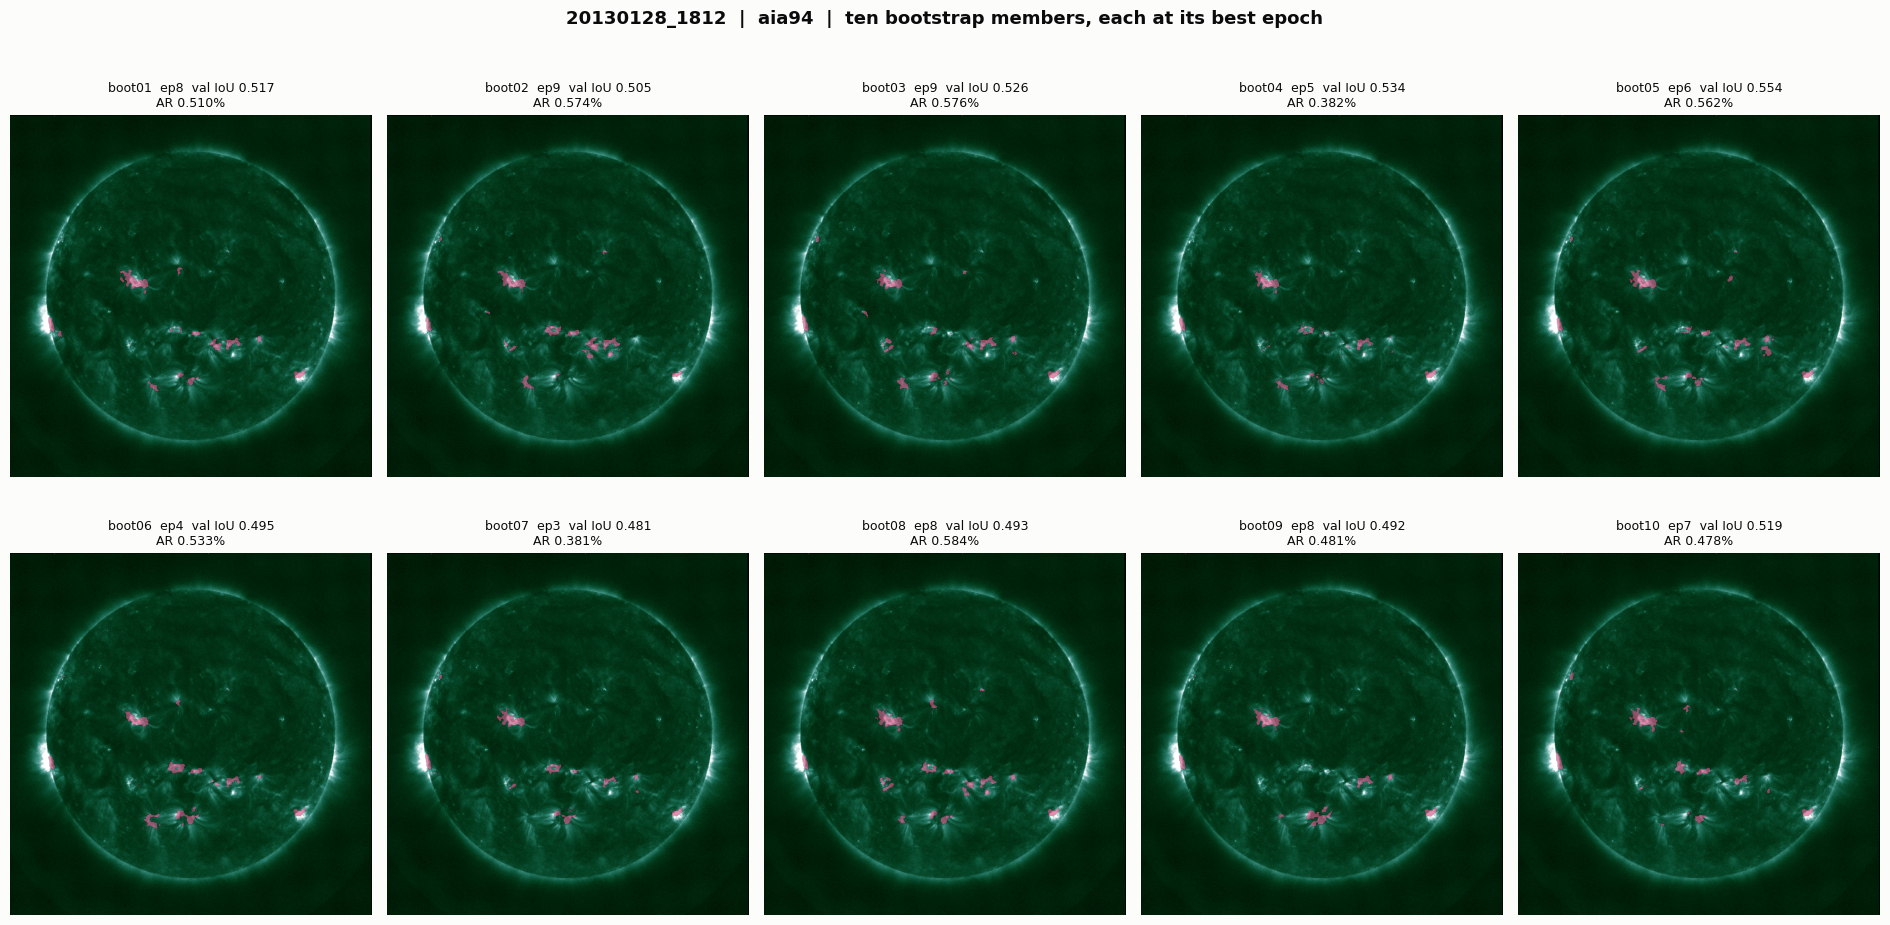

predicted AR fraction across members: mean 0.00506  sd 0.00076  (15% of mean)
  min 0.00381 (boot07)   max 0.00584 (boot08)   max/min ratio 1.53x


In [4]:
# 2013-01-28 is near solar maximum and is NOT on the epoch-selection day.
FRAME = "20130128_1812"
CHANNEL = "aia94"

image = load_channel(FRAME, CHANNEL)
vmin, vmax = channel_clim(CHANNEL, image)
img_small = block_mean(image, 4)

fig, axes = plt.subplots(2, 5, figsize=(19, 9.4))
fig.suptitle(
    f"{FRAME}  |  {CHANNEL}  |  ten bootstrap members, each at its best epoch",
    fontsize=13, fontweight="bold", color=INK, y=1.02,
)

fracs = {}
for ax, member in zip(axes.ravel(), MEMBERS):
    prob = load_probability(FRAME, member)
    mask = prob > THRESHOLD
    fracs[member] = float(mask.mean())
    epoch, iou = BEST[member]

    ax.imshow(img_small, cmap=channel_cmap(CHANNEL), vmin=vmin, vmax=vmax)
    # block_max so a mask covering <1% of the frame survives downsampling.
    ax.imshow(np.ma.masked_where(~block_max(mask, 4), np.ones_like(img_small)),
              cmap=ListedColormap([MASK_FILL]), alpha=0.65, vmin=0, vmax=1)
    ax.set_title(f"{member}  ep{epoch}  val IoU {iou:.3f}\nAR {100 * fracs[member]:.3f}%",
                 fontsize=9, color=INK)
    ax.axis("off")

# Blank any leftover cells, so a partial ensemble doesn't show empty plot boxes.
for ax in axes.ravel()[len(MEMBERS):]:
    ax.axis("off")

# h_pad keeps the second row's two-line titles off the first row's images;
# tight_layout under-reserves for titles on axes with axis("off").
plt.tight_layout(h_pad=3.0)
plt.show()

v = np.array(list(fracs.values()))
print(f"predicted AR fraction across members: mean {v.mean():.5f}  sd {v.std(ddof=1):.5f}  "
      f"({100 * v.std(ddof=1) / v.mean():.0f}% of mean)")
print(f"  min {v.min():.5f} ({min(fracs, key=fracs.get)})   "
      f"max {v.max():.5f} ({max(fracs, key=fracs.get)})   "
      f"max/min ratio {v.max() / v.min():.2f}x")

## 2. Where do they agree?

The agreement map counts, per pixel, how many of the ten members called it active
region. 0 means none did, 10 means all did. Intermediate values are exactly the
pixels the bootstrap is uncertain about.

Left is the agreement map alone, right is it over the channel image.

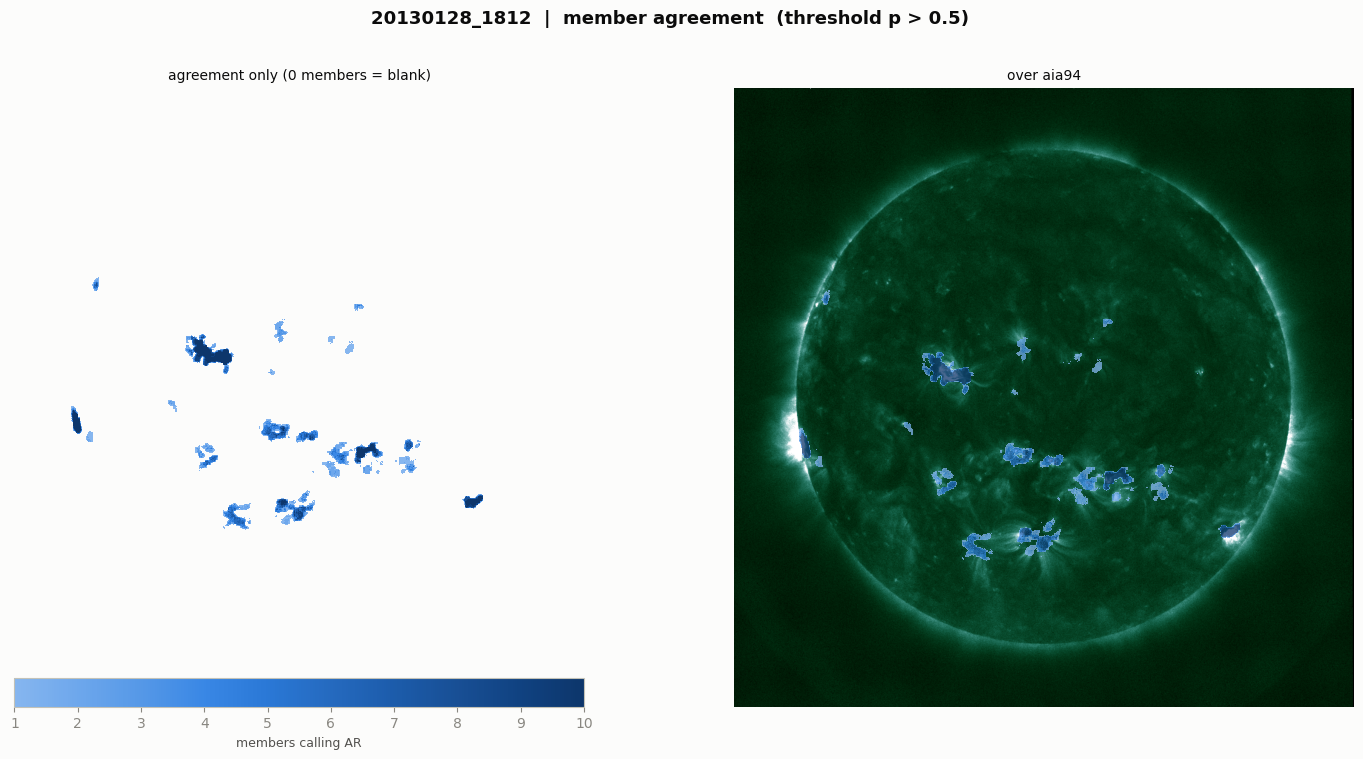

In [5]:
count = agreement_map(FRAME)
n = len(MEMBERS)

fig, axes = plt.subplots(1, 2, figsize=(15, 7.4))
fig.suptitle(f"{FRAME}  |  member agreement  (threshold p > {THRESHOLD})",
             fontsize=13, fontweight="bold", color=INK, y=1.02)

# block_max keeps any flagged pixel; on the count field it reports the strongest
# agreement in each block rather than washing it out.
small = block_max(count, 4)

im = axes[0].imshow(np.ma.masked_where(small == 0, small), cmap=SEQ_AGREE,
                    norm=Normalize(1, n), interpolation="nearest")
axes[0].set_title("agreement only (0 members = blank)", fontsize=10, color=INK)
cb = fig.colorbar(im, ax=axes[0], fraction=0.046, pad=0.02,
                  ticks=range(1, n + 1), orientation="horizontal")
cb.set_label("members calling AR", color=INK_2, fontsize=9)
cb.ax.tick_params(colors=MUTED)

axes[1].imshow(img_small, cmap=channel_cmap(CHANNEL), vmin=vmin, vmax=vmax)
axes[1].imshow(np.ma.masked_where(small == 0, small), cmap=SEQ_AGREE,
               norm=Normalize(1, n), alpha=0.75, interpolation="nearest")
axes[1].set_title(f"over {CHANNEL}", fontsize=10, color=INK)

for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

### How much of the predicted area is unanimous?

A bar per agreement level. The `k = 0` bin holds ~99 % of the frame (everything
nobody called AR) and is reported as a number rather than drawn, which would
flatten every other bar to nothing.

The shape of this distribution is the headline: a confident ensemble is
**U-shaped** (pixels are either unanimously AR or unanimously not), a
disagreeing one is flat.

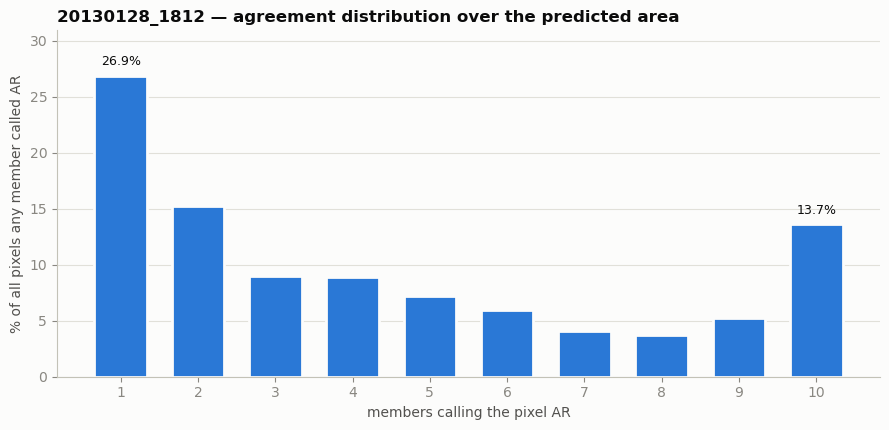

no member called AR :   16,581,781 px  (98.835% of frame)
at least one member :      195,435 px  (1.165% of frame)
all 10 members      :       26,690 px  (13.7% of the predicted area)

The union is 7.3x the unanimous core — the ensemble's footprint
depends heavily on how many members you require to agree.


In [6]:
levels = np.arange(1, n + 1)
counts = np.array([(count == k).sum() for k in levels])
none = int((count == 0).sum())
any_ar = int(counts.sum())
unanimous = int(counts[-1])

fig, ax = plt.subplots(figsize=(9, 4.4))
bars = ax.bar(levels, 100 * counts / any_ar, width=0.68, color=SERIES_1,
              edgecolor="#fcfcfb", linewidth=2)  # 2px surface gap between fills
# Direct-label only the ends: the story is how much sits at k=1 vs k=10.
for k in (0, len(levels) - 1):
    b = bars[k]
    ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 0.9,
            f"{b.get_height():.1f}%", ha="center", fontsize=9, color=INK)

recessive(ax)
ax.set_ylim(0, 1.15 * (100 * counts / any_ar).max())  # headroom for the end labels
ax.set_xticks(levels)
ax.set_xlabel("members calling the pixel AR", color=INK_2)
ax.set_ylabel("% of all pixels any member called AR", color=INK_2)
ax.set_title(f"{FRAME} — agreement distribution over the predicted area",
             fontsize=12, fontweight="bold", color=INK, loc="left")
plt.tight_layout()
plt.show()

print(f"no member called AR : {none:>12,} px  ({100 * none / count.size:.3f}% of frame)")
print(f"at least one member : {any_ar:>12,} px  ({100 * any_ar / count.size:.3f}% of frame)")
print(f"all {n} members      : {unanimous:>12,} px  "
      f"({100 * unanimous / any_ar:.1f}% of the predicted area)")
print(f"\nThe union is {any_ar / max(unanimous, 1):.1f}x the unanimous core — the "
      f"ensemble's footprint\ndepends heavily on how many members you require to agree.")

## 3. Spread across all 15 frames

Section 1 was one frame. This is every frame, to separate *"members disagree"*
from *"this particular frame is hard"*.

Rows are members, columns are frames, colour is the predicted AR fraction. A
member that is systematically heavy shows as a dark row; a frame that is
genuinely active shows as a dark column. Frames on the epoch-selection day are
marked `*`.

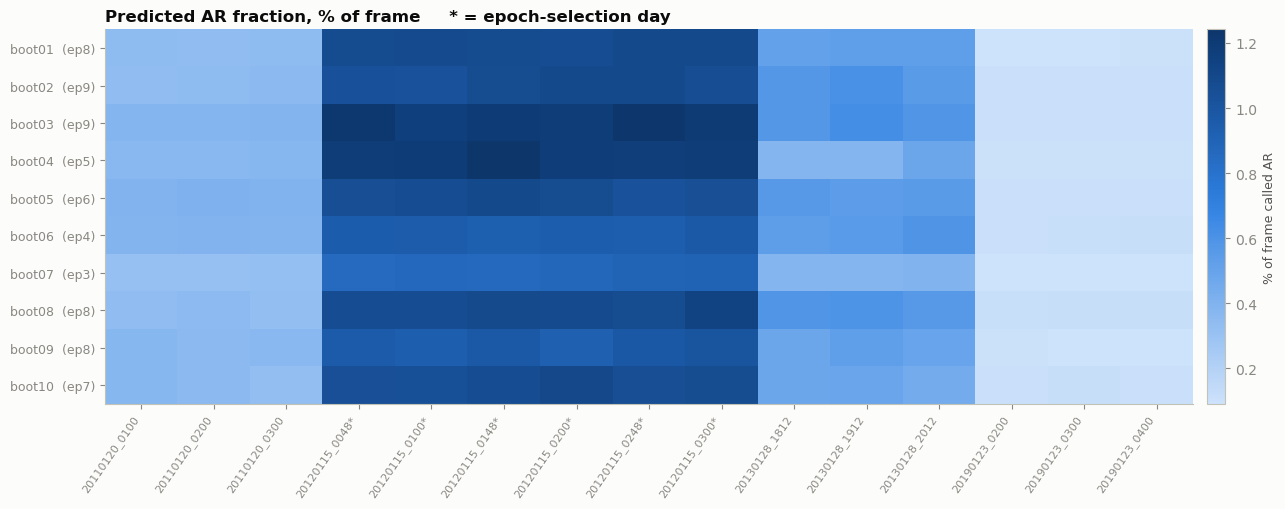

Per-member, averaged over all 15 frames:

        mean %    sd %  rank  val IoU
boot01  0.6232  0.4096     6   0.5170
boot02  0.6288  0.3964     5   0.5050
boot03  0.6962  0.4543     1   0.5256
boot04  0.6523  0.4689     2   0.5344
boot05  0.6339  0.3888     4   0.5539
boot06  0.5906  0.3351     8   0.4950
boot07  0.5100  0.3263    10   0.4812
boot08  0.6391  0.4047     3   0.4927
boot09  0.5771  0.3526     9   0.4918
boot10  0.6109  0.3987     7   0.5194


In [7]:
# ~2 s per member-frame off EFS, so build the table once and reuse it.
table = pd.DataFrame(
    [[float((load_probability(f, m) > THRESHOLD).mean()) for f in frames] for m in MEMBERS],
    index=MEMBERS, columns=frames,
)

labels = [f"{f}*" if f.startswith(SELECTION_DAY) else f for f in frames]

fig, ax = plt.subplots(figsize=(13, 5.2))
im = ax.imshow(100 * table.values, cmap=SEQ, aspect="auto", interpolation="nearest")
ax.set_xticks(range(len(frames)), labels, rotation=55, ha="right", fontsize=8)
ax.set_yticks(range(len(MEMBERS)),
              [f"{m}  (ep{BEST[m][0]})" for m in MEMBERS], fontsize=9)
ax.set_title("Predicted AR fraction, % of frame     * = epoch-selection day",
             fontsize=12, fontweight="bold", color=INK, loc="left")
ax.grid(False)
cb = fig.colorbar(im, ax=ax, fraction=0.025, pad=0.012)
cb.set_label("% of frame called AR", color=INK_2, fontsize=9)
cb.ax.tick_params(colors=MUTED)
plt.tight_layout()
plt.show()

summary = pd.DataFrame({
    "mean %": 100 * table.mean(axis=1),
    "sd %": 100 * table.std(axis=1, ddof=1),
    "rank": (100 * table.mean(axis=1)).rank(ascending=False).astype(int),
    "val IoU": [BEST[m][1] for m in MEMBERS],
})
print("Per-member, averaged over all 15 frames:\n")
print(summary.round(4).to_string())

### Per-frame spread

Each frame's ten member predictions as dots, with the ensemble mean marked. The
vertical extent of a column is the bootstrap uncertainty for that frame.

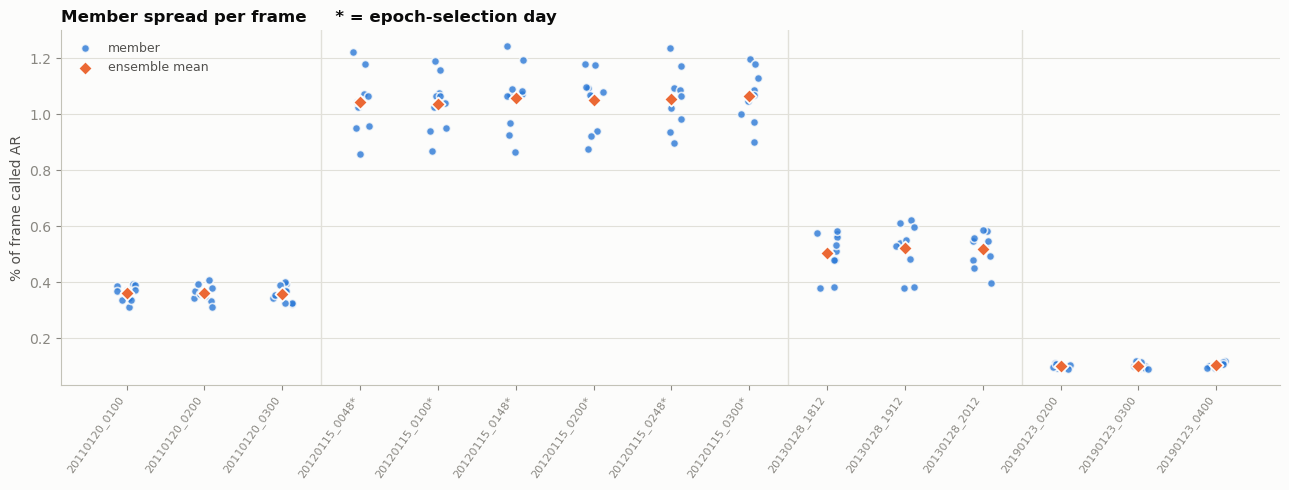

across-member spread, as % of that frame's mean:
  median over all 15 frames   9.5%
  epoch-selection day (n=6)   9.8%
  clean frames        (n=9)   10.0%


In [8]:
fig, ax = plt.subplots(figsize=(13, 5))
x = np.arange(len(frames))
rng = np.random.default_rng(0)  # fixed jitter so the figure is reproducible

for i, f in enumerate(frames):
    vals = 100 * table[f].values
    ax.scatter(np.full_like(vals, i) + rng.uniform(-0.13, 0.13, vals.size), vals,
               s=34, color=SERIES_1, alpha=0.8, zorder=3,
               edgecolor="#fcfcfb", linewidth=1.2,  # 2px surface ring on overlap
               label="member" if i == 0 else None)

means = 100 * table.mean(axis=0).values
# Markers, not a line. The x axis is 15 frames from four separate days spanning
# eight years; joining them would draw a trend through gaps of up to a year.
ax.scatter(x, means, marker="D", s=52, color=SERIES_2, zorder=4,
           edgecolor="#fcfcfb", linewidth=1.2, label="ensemble mean")

# Hairline separators between days, so the groups read as groups.
day_of = [f[:8] for f in frames]
for i in range(1, len(frames)):
    if day_of[i] != day_of[i - 1]:
        ax.axvline(i - 0.5, color=GRID, lw=1, zorder=1)

recessive(ax)
ax.set_xticks(x, labels, rotation=55, ha="right", fontsize=8)
ax.set_ylabel("% of frame called AR", color=INK_2)
ax.set_title("Member spread per frame     * = epoch-selection day",
             fontsize=12, fontweight="bold", color=INK, loc="left")
ax.legend(frameon=False, loc="upper left", fontsize=9, labelcolor=INK_2)
plt.tight_layout()
plt.show()

cv = 100 * table.std(axis=0, ddof=1) / table.mean(axis=0)
sel = [f.startswith(SELECTION_DAY) for f in frames]
print(f"across-member spread, as % of that frame's mean:")
print(f"  median over all 15 frames   {cv.median():.1f}%")
print(f"  epoch-selection day (n={sum(sel)})   {cv[sel].mean():.1f}%")
print(f"  clean frames        (n={15 - sum(sel)})   {cv[[not s for s in sel]].mean():.1f}%")

## 4. Where the disagreement actually is

Zoomed on the most contested region of the frame — the window holding the most
pixels that *some but not all* members called AR. Contours mark where the
agreement fraction crosses 0.5 and 0.8.

This is the view that says what kind of disagreement it is: a shared detection
whose **boundary** the members place differently, or an active region some
members **miss entirely**.

The agreement field **cannot be contoured as it stands** — it only takes the
values k/10, and its edges follow Surya's 16 px patch grid, so a contour on the
raw field traces that staircase and every isolated speckle. It is first smoothed
to the model's resolution limit (Gaussian, FWHM = one patch) using
`false_color.smooth_to_model_resolution`, and the smoothed field is contoured.

smoothed with FWHM 16 px (sigma 6.79 px);  raw max 1.00 -> smoothed max 1.00


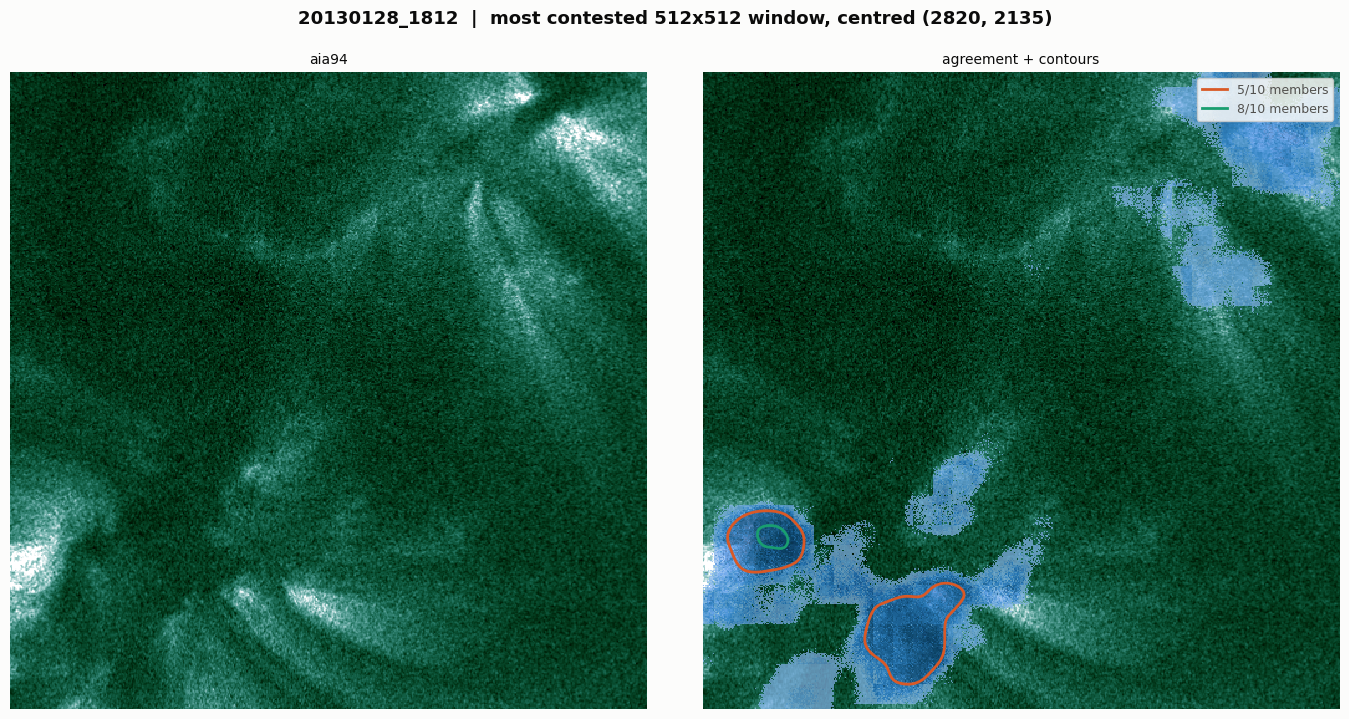

in this window: 39,329 px called AR by >=1 member, 112 px by all 10
contested (1..9 members): 39,217 px


In [9]:
import sys

from scipy.ndimage import uniform_filter

if "." not in sys.path:
    sys.path.insert(0, ".")
import false_color as fcolor  # the smoothing helper, shared with view_results.ipynb

contested = (count > 0) & (count < n)
# Coarse density of contested pixels, then take the densest window.
WIN = 512
density = uniform_filter(contested.astype(np.float32), size=WIN, mode="constant")
cy, cx = np.unravel_index(np.argmax(density), density.shape)
y0, x0 = max(0, cy - WIN // 2), max(0, cx - WIN // 2)
y1, x1 = min(count.shape[0], y0 + WIN), min(count.shape[1], x0 + WIN)

# Smooth the whole frame, then crop. Smoothing the crop instead would treat the
# window edge as the end of the data and bend the contour there.
smoothed = fcolor.smooth_to_model_resolution(count / n, fcolor.SURYA_PATCH_PX)
print(f"smoothed with FWHM {fcolor.SURYA_PATCH_PX} px "
      f"(sigma {fcolor.SURYA_PATCH_PX / 2.3548:.2f} px);  "
      f"raw max {(count / n).max():.2f} -> smoothed max {smoothed.max():.2f}")

sub_img = image[y0:y1, x0:x1]
sub_cnt = count[y0:y1, x0:x1]
fraction = smoothed[y0:y1, x0:x1]

fig, axes = plt.subplots(1, 2, figsize=(14, 7))
fig.suptitle(f"{FRAME}  |  most contested {WIN}x{WIN} window, centred ({cy}, {cx})",
             fontsize=13, fontweight="bold", color=INK, y=1.02)

axes[0].imshow(sub_img, cmap=channel_cmap(CHANNEL), vmin=vmin, vmax=vmax,
               interpolation="nearest")
axes[0].set_title(f"{CHANNEL}", fontsize=10, color=INK)

axes[1].imshow(sub_img, cmap=channel_cmap(CHANNEL), vmin=vmin, vmax=vmax,
               interpolation="nearest")
im = axes[1].imshow(np.ma.masked_where(sub_cnt == 0, sub_cnt), cmap=SEQ_AGREE,
                    norm=Normalize(1, n), alpha=0.7, interpolation="nearest")
handles = []
for level, colour in sorted(CONTOUR.items()):
    # Smoothing is a local average, so a high level needs a solid patch-sized
    # region of agreement, not scattered unanimous speckle. Report an empty
    # contour rather than silently drawing nothing.
    if (fraction >= level).any() and not (fraction >= level).all():
        axes[1].contour(fraction, levels=[level], colors=[colour], linewidths=2)
        handles.append(plt.Line2D([], [], color=colour, lw=2,
                                  label=f"{int(round(level * n))}/{n} members"))
    else:
        print(f"  contour {level:.1f} EMPTY — smoothed field never crosses it here")
axes[1].set_title("agreement + contours", fontsize=10, color=INK)
if handles:
    axes[1].legend(handles=handles, loc="upper right", fontsize=9,
                   framealpha=0.85, labelcolor=INK_2)

for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

print(f"in this window: {int((sub_cnt > 0).sum()):,} px called AR by >=1 member, "
      f"{int((sub_cnt == n).sum()):,} px by all {n}")
print(f"contested (1..{n - 1} members): {int(((sub_cnt > 0) & (sub_cnt < n)).sum()):,} px")

## 5. Browse any frame and channel

Redraws sections 1 and 2 for any combination without editing the constants above.
Each redraw reads ~10 × 34 MB off EFS, so give it a few seconds.

In [10]:
import ipywidgets as widgets

CHANNELS = ["aia94", "aia131", "aia171", "aia193", "aia211", "aia304", "aia335",
            "aia1600", "hmi_m", "hmi_bx", "hmi_by", "hmi_bz", "hmi_v"]


def redraw(frame, channel):
    img = load_channel(frame, channel)
    lo, hi = channel_clim(channel, img)
    small = block_mean(img, 4)
    cmap = channel_cmap(channel)
    note = "  (epoch-selection day)" if frame.startswith(SELECTION_DAY) else ""

    fig, axes = plt.subplots(2, 5, figsize=(19, 9.4))
    fig.suptitle(f"{frame}  |  {channel}{note}", fontsize=13, fontweight="bold",
                 color=INK, y=1.02)
    for ax, member in zip(axes.ravel(), MEMBERS):
        mask = load_probability(frame, member) > THRESHOLD
        ax.imshow(small, cmap=cmap, vmin=lo, vmax=hi)
        ax.imshow(np.ma.masked_where(~block_max(mask, 4), np.ones_like(small)),
                  cmap=ListedColormap([MASK_FILL]), alpha=0.65, vmin=0, vmax=1)
        ax.set_title(f"{member}  ep{BEST[member][0]}\nAR {100 * mask.mean():.3f}%",
                     fontsize=9, color=INK)
        ax.axis("off")
    for ax in axes.ravel()[len(MEMBERS):]:
        ax.axis("off")
    plt.tight_layout(h_pad=3.0)
    plt.show()

    cnt = block_max(agreement_map(frame), 4)
    fig, ax = plt.subplots(figsize=(7.5, 7))
    ax.imshow(small, cmap=cmap, vmin=lo, vmax=hi)
    im = ax.imshow(np.ma.masked_where(cnt == 0, cnt), cmap=SEQ_AGREE,
                   norm=Normalize(1, len(MEMBERS)), alpha=0.75, interpolation="nearest")
    cb = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.02, ticks=range(1, len(MEMBERS) + 1))
    cb.set_label("members calling AR", color=INK_2, fontsize=9)
    cb.ax.tick_params(colors=MUTED)
    ax.set_title(f"agreement — {frame}", fontsize=11, color=INK)
    ax.axis("off")
    plt.tight_layout()
    plt.show()


widgets.interact(
    redraw,
    frame=widgets.Dropdown(options=frames, value=FRAME, description="frame"),
    channel=widgets.Dropdown(options=CHANNELS, value=CHANNEL, description="channel"),
)

interactive(children=(Dropdown(description='frame', index=9, options=('20110120_0100', '20110120_0200', '20110…

<function __main__.redraw(frame, channel)>

## 6. Run manifest

One row per inference, written by `run_bootstrap_inference.py`.

In [11]:
manifest = pd.read_csv(os.path.join(INFER_ROOT, "manifest.csv"))
print(f"{len(manifest)} inferences  |  "
      f"total GPU forward time {manifest.fwd_s.sum() / 60:.1f} min  |  "
      f"read time {manifest.read_s.sum() / 60:.1f} min")
manifest.head(12)

150 inferences  |  total GPU forward time 9.8 min  |  read time 11.3 min


,member,epoch,val_iou,file,data_time,pred_frac,read_s,fwd_s
0,boot01,8,0.517,20110120_0100,2011-01-20T01:00,0.003441,4.8,4.1
1,boot01,8,0.517,20110120_0200,2011-01-20T02:00,0.003347,4.7,3.9
2,boot01,8,0.517,20110120_0300,2011-01-20T03:00,0.003446,5.4,4.0
3,boot01,8,0.517,20120115_0048,2012-01-15T00:48,0.010737,5.1,3.9
4,boot01,8,0.517,20120115_0100,2012-01-15T01:00,0.010774,4.8,3.9
5,boot01,8,0.517,20120115_0148,2012-01-15T01:48,0.010734,5.4,3.9
6,boot01,8,0.517,20120115_0200,2012-01-15T02:00,0.010656,5.5,4.0
7,boot01,8,0.517,20120115_0248,2012-01-15T02:48,0.010938,5.7,4.0
8,boot01,8,0.517,20120115_0300,2012-01-15T03:00,0.010875,5.3,4.0
9,boot01,8,0.517,20130128_1812,2013-01-28T18:12,0.005106,5.8,3.9
